# bernacchi2003

Generated by GreenSloth from this model's validations.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from mxlpy import scan

In [2]:
import math

import numpy as np
import sympy.physics.units as su
from sympy.physics.units.quantities import Quantity

from mxlpy import Slider, SteadyStateModelBuilder

def _derived_Tk(T_leaf):
    return T_leaf + 273.15

def _derived_Tk273(T_leaf):
    return T_leaf + 273

def _derived_Gamma_star(R, c_Gamma_star, dHa_Gamma_star, Tk):
    return np.exp((c_Gamma_star) - ((dHa_Gamma_star) / (R * Tk)))

def _derived_Kc(R, c_Kc, dHa_Kc, Tk):
    return np.exp((c_Kc) - ((dHa_Kc) / (R * Tk)))

def _derived_Ko(R, c_Ko, dHa_Ko, Tk):
    return np.exp((c_Ko) - ((dHa_Ko) / (R * Tk)))

def _derived_Vcmax(Vcmax25, R, c_Vcmax, dHa_Vcmax, Tk):
    return Vcmax25 * np.exp((c_Vcmax) - ((dHa_Vcmax) / (R * Tk)))

def _derived_Rd(Rd25, R, c_Rd, dHa_Rd, Tk):
    return Rd25 * np.exp((c_Rd) - ((dHa_Rd) / (R * Tk)))

def _derived_Jmax(Jmax25, R, c_Jmax, dHa_Jmax, Tk):
    return Jmax25 * np.exp((c_Jmax) - ((dHa_Jmax) / (R * Tk)))

def _derived_Theta(T_leaf, Theta_a, Theta_b, Theta_c):
    return (Theta_a + Theta_b * T_leaf) - (Theta_c * (T_leaf) ** (2))

def _derived_Phi(T_leaf, Phi_a, Phi_b, Phi_c):
    return (Phi_a + Phi_b * T_leaf) - (Phi_c * (T_leaf) ** (2))

def _derived_Q2(Q, alpha_l, beta, Phi):
    return Q * alpha_l * Phi * beta

def _derived_J(Jmax, Theta, Q2):
    return ((Q2 + Jmax) - (np.pow(((Q2 + Jmax) ** (2)) - (4 * Theta * Q2 * Jmax), 1 / 2))) / (2 * Theta)

def _derived_Wc(Ci, O, Kc, Ko, Vcmax):
    return (Vcmax * Ci) / (Ci + Kc * (1 + (O) / (Ko)))

def _derived_Wj(Ci, Gamma_star, J):
    return (J * Ci) / (4.5 * Ci + 10.5 * Gamma_star)

def _derived_A(Ci, Gamma_star, Rd, Wc, Wj):
    return (((1) - ((Gamma_star) / (Ci))) * min(Wc, Wj)) - (Rd)

def _derived_Jmax_acc(T_leaf, Tg, Jmax25, k_Jacc, mg_Jacc, sg_Jacc, ml_Jacc, sl_Jacc):
    return Jmax25 * k_Jacc * np.exp(-0.5 * ((((Tg) - (mg_Jacc)) / (sg_Jacc)) ** (2) + (((T_leaf) - (ml_Jacc)) / (sl_Jacc)) ** (2)))

def _derived_Theta_acc(T_leaf, Tg, k_Thacc, mg_Thacc, sg_Thacc, ml_Thacc, sl_Thacc):
    return k_Thacc * np.exp(-0.5 * ((((Tg) - (mg_Thacc)) / (sg_Thacc)) ** (2) + (((T_leaf) - (ml_Thacc)) / (sl_Thacc)) ** (2)))

def _derived_J_acc(Q2, Jmax_acc, Theta_acc):
    return ((Q2 + Jmax_acc) - (np.pow(((Q2 + Jmax_acc) ** (2)) - (4 * Theta_acc * Q2 * Jmax_acc), 1 / 2))) / (2 * Theta_acc)

def _derived_Wj_acc(Ci, Gamma_star, J_acc):
    return (J_acc * Ci) / (4.5 * Ci + 10.5 * Gamma_star)

def _derived_A_acc(Ci, Gamma_star, Rd, Wc, Wj_acc):
    return (((1) - ((Gamma_star) / (Ci))) * min(Wc, Wj_acc)) - (Rd)

def _derived_Jf14(R, c_Jf14, dHa_Jf14, dHd_Jf14, dS_Jf14, Tk273):
    return (np.exp((c_Jf14) - ((dHa_Jf14) / (R * Tk273)))) / (1 + np.exp(((dS_Jf14 * Tk273) - (dHd_Jf14)) / (R * Tk273)))

def _derived_Jf25(R, c_Jf25, dHa_Jf25, Tk273):
    return np.exp((c_Jf25) - ((dHa_Jf25) / (R * Tk273)))

def _derived_Jf35(R, c_Jf35, dHa_Jf35, Tk273):
    return np.exp((c_Jf35) - ((dHa_Jf35) / (R * Tk273)))

def _derived_Theta14(T_leaf, Theta14_a, Theta14_b, Theta14_c):
    return (Theta14_a + Theta14_b * T_leaf) - (Theta14_c * (T_leaf) ** (2))

def _derived_Theta35(T_leaf, Theta35_a, Theta35_b, Theta35_c):
    return (Theta35_a + Theta35_b * T_leaf) - (Theta35_c * (T_leaf) ** (2))

def get_model() -> SteadyStateModelBuilder:
    m = SteadyStateModelBuilder()
    m.add_parameter("Ci", 300, unit=0.000001, display_name="Ci", tex_name="C_i", slider=Slider(min="50", max="2000", step="5"))
    m.add_parameter("Q", 1000, unit=su.mol*su.micro/(su.meter**2*su.second), display_name="Q", tex_name="Q", slider=Slider(min="0", max="2000", step="10"))
    m.add_parameter("O", 210, unit=0.001, display_name="O", tex_name="O", slider=Slider(min="0", max="400", step="5"))
    m.add_parameter("T_leaf", 25, unit=Quantity("celsius", abbrev="°C"), display_name="T_leaf", tex_name="T_l", slider=Slider(min="10", max="40", step="0.5"))
    m.add_parameter("Tg", 25, unit=Quantity("celsius", abbrev="°C"), display_name="Tg", tex_name="T_g", slider=Slider(min="14", max="35", step="0.5"))
    m.add_parameter("Vcmax25", 80, unit=su.mol*su.micro/(su.meter**2*su.second), display_name="Vcmax25", tex_name="V_{c,max,25}", slider=Slider(min="0", max="200", step="1"))
    m.add_parameter("Jmax25", 136, unit=su.mol*su.micro/(su.meter**2*su.second), display_name="Jmax25", tex_name="J_{max,25}", slider=Slider(min="0", max="400", step="1"))
    m.add_parameter("Rd25", 1, unit=su.mol*su.micro/(su.meter**2*su.second), display_name="Rd25", tex_name="R_{d,25}", slider=Slider(min="0", max="5", step="0.05"))
    m.add_parameter("alpha_l", 0.85, unit=None, display_name="alpha_l", tex_name="\\alpha_l", slider=Slider(min="0.5", max="1", step="0.01"))
    m.add_parameter("beta", 0.5, unit=None, display_name="beta", tex_name="\\beta", slider=Slider(min="0.3", max="0.7", step="0.01"))
    m.add_parameter("R", 0.008314, unit=su.joule*su.kilo/(su.kelvin*su.mol), tex_name="R")
    m.add_parameter("c_Gamma_star", 19.02, unit=None, tex_name="c_{\\Gamma^*}")
    m.add_parameter("dHa_Gamma_star", 37.83, unit=su.joule*su.kilo/su.mol, tex_name="\\Delta H_{a,\\Gamma^*}")
    m.add_parameter("c_Kc", 38.05, unit=None, tex_name="c_{K_c}")
    m.add_parameter("dHa_Kc", 79.43, unit=su.joule*su.kilo/su.mol, tex_name="\\Delta H_{a,K_c}")
    m.add_parameter("c_Ko", 20.3, unit=None, tex_name="c_{K_o}")
    m.add_parameter("dHa_Ko", 36.38, unit=su.joule*su.kilo/su.mol, tex_name="\\Delta H_{a,K_o}")
    m.add_parameter("c_Vcmax", 26.35, unit=None, tex_name="c_{V_{c,max}}")
    m.add_parameter("dHa_Vcmax", 65.33, unit=su.joule*su.kilo/su.mol, tex_name="\\Delta H_{a,V_{c,max}}")
    m.add_parameter("c_Rd", 18.72, unit=None, tex_name="c_{R_d}")
    m.add_parameter("dHa_Rd", 46.39, unit=su.joule*su.kilo/su.mol, tex_name="\\Delta H_{a,R_d}")
    m.add_parameter("c_Jmax", 17.57, unit=None, tex_name="c_{J_{max}}")
    m.add_parameter("dHa_Jmax", 43.54, unit=su.joule*su.kilo/su.mol, tex_name="\\Delta H_{a,J_{max}}")
    m.add_parameter("c_Jf25", 17.57, unit=None, tex_name="c_{J_{max,f,25}}")
    m.add_parameter("dHa_Jf25", 43.5, unit=su.joule*su.kilo/su.mol, tex_name="\\Delta H_{a,J_{max,f,25}}")
    m.add_parameter("c_Jf35", 13.22, unit=None, tex_name="c_{J_{max,f,35}}")
    m.add_parameter("dHa_Jf35", 32.8, unit=su.joule*su.kilo/su.mol, tex_name="\\Delta H_{a,J_{max,f,35}}")
    m.add_parameter("c_Jf14", 22.2, unit=None, tex_name="c_{J_{max,f,14}}")
    m.add_parameter("dHa_Jf14", 54.9, unit=su.joule*su.kilo/su.mol, tex_name="\\Delta H_{a,J_{max,f,14}}")
    m.add_parameter("dHd_Jf14", 437.7, unit=su.joule*su.kilo/su.mol, tex_name="\\Delta H_{d,J_{max,f,14}}")
    m.add_parameter("dS_Jf14", 1.4, unit=su.joule*su.kilo/(su.kelvin*su.mol), tex_name="\\Delta S_{J_{max,f,14}}")
    m.add_parameter("Phi_a", 0.352, unit=None, tex_name="a_{\\Phi_{PSII,max,l}}")
    m.add_parameter("Phi_b", 0.022, unit=1/Quantity("celsius", abbrev="°C"), tex_name="b_{\\Phi_{PSII,max,l}}")
    m.add_parameter("Phi_c", 0.00034, unit=1/Quantity("celsius", abbrev="°C")**2, tex_name="c_{\\Phi_{PSII,max,l}}")
    m.add_parameter("Theta_a", 0.76, unit=None, tex_name="a_{\\Theta_{PSII}}")
    m.add_parameter("Theta_b", 0.018, unit=1/Quantity("celsius", abbrev="°C"), tex_name="b_{\\Theta_{PSII}}")
    m.add_parameter("Theta_c", 0.00037, unit=1/Quantity("celsius", abbrev="°C")**2, tex_name="c_{\\Theta_{PSII}}")
    m.add_parameter("Theta14_a", 0.66, unit=None, tex_name="a_{\\Theta_{PSII,14}}")
    m.add_parameter("Theta14_b", 0.021, unit=1/Quantity("celsius", abbrev="°C"), tex_name="b_{\\Theta_{PSII,14}}")
    m.add_parameter("Theta14_c", 0.00045, unit=1/Quantity("celsius", abbrev="°C")**2, tex_name="c_{\\Theta_{PSII,14}}")
    m.add_parameter("Theta35_a", 0.54, unit=None, tex_name="a_{\\Theta_{PSII,35}}")
    m.add_parameter("Theta35_b", 0.023, unit=1/Quantity("celsius", abbrev="°C"), tex_name="b_{\\Theta_{PSII,35}}")
    m.add_parameter("Theta35_c", 0.00033, unit=1/Quantity("celsius", abbrev="°C")**2, tex_name="c_{\\Theta_{PSII,35}}")
    m.add_parameter("k_Jacc", 1.92, unit=None, tex_name="k_{J}")
    m.add_parameter("mg_Jacc", 26.42, unit=Quantity("celsius", abbrev="°C"), tex_name="m_{g,J}")
    m.add_parameter("sg_Jacc", 17.97, unit=Quantity("celsius", abbrev="°C"), tex_name="s_{g,J}")
    m.add_parameter("ml_Jacc", 47.04, unit=Quantity("celsius", abbrev="°C"), tex_name="m_{l,J}")
    m.add_parameter("sl_Jacc", 19.38, unit=Quantity("celsius", abbrev="°C"), tex_name="s_{l,J}")
    m.add_parameter("k_Thacc", 0.85, unit=None, tex_name="k_{\\Theta}")
    m.add_parameter("mg_Thacc", 25.8, unit=Quantity("celsius", abbrev="°C"), tex_name="m_{g,\\Theta}")
    m.add_parameter("sg_Thacc", 14.84, unit=Quantity("celsius", abbrev="°C"), tex_name="s_{g,\\Theta}")
    m.add_parameter("ml_Thacc", 29.2, unit=Quantity("celsius", abbrev="°C"), tex_name="m_{l,\\Theta}")
    m.add_parameter("sl_Thacc", 17.99, unit=Quantity("celsius", abbrev="°C"), tex_name="s_{l,\\Theta}")
    m.add_derived("Tk", _derived_Tk, args=["T_leaf"], unit=su.kelvin, tex_name="T_k")
    m.add_derived("Tk273", _derived_Tk273, args=["T_leaf"], unit=su.kelvin, tex_name="T_{k,273}")
    m.add_derived("Gamma_star", _derived_Gamma_star, args=["R", "c_Gamma_star", "dHa_Gamma_star", "Tk"], unit=0.000001, display_name="Gamma_star", tex_name="\\Gamma^*")
    m.add_derived("Kc", _derived_Kc, args=["R", "c_Kc", "dHa_Kc", "Tk"], unit=0.000001, display_name="Kc", tex_name="K_c")
    m.add_derived("Ko", _derived_Ko, args=["R", "c_Ko", "dHa_Ko", "Tk"], unit=0.001, display_name="Ko", tex_name="K_o")
    m.add_derived("Vcmax", _derived_Vcmax, args=["Vcmax25", "R", "c_Vcmax", "dHa_Vcmax", "Tk"], unit=su.mol*su.micro/(su.meter**2*su.second), display_name="Vcmax", tex_name="V_{c,max}")
    m.add_derived("Rd", _derived_Rd, args=["Rd25", "R", "c_Rd", "dHa_Rd", "Tk"], unit=su.mol*su.micro/(su.meter**2*su.second), display_name="Rd", tex_name="R_d")
    m.add_derived("Jmax", _derived_Jmax, args=["Jmax25", "R", "c_Jmax", "dHa_Jmax", "Tk"], unit=su.mol*su.micro/(su.meter**2*su.second), display_name="Jmax", tex_name="J_{max}")
    m.add_derived("Theta", _derived_Theta, args=["T_leaf", "Theta_a", "Theta_b", "Theta_c"], unit=None, display_name="Theta", tex_name="\\Theta_{PSII}")
    m.add_derived("Phi", _derived_Phi, args=["T_leaf", "Phi_a", "Phi_b", "Phi_c"], unit=None, display_name="Phi", tex_name="\\Phi_{PSII,max}")
    m.add_derived("Q2", _derived_Q2, args=["Q", "alpha_l", "beta", "Phi"], unit=su.mol*su.micro/(su.meter**2*su.second), display_name="Q2", tex_name="Q_2")
    m.add_derived("J", _derived_J, args=["Jmax", "Theta", "Q2"], unit=su.mol*su.micro/(su.meter**2*su.second), display_name="J", tex_name="J")
    m.add_derived("Wc", _derived_Wc, args=["Ci", "O", "Kc", "Ko", "Vcmax"], unit=su.mol*su.micro/(su.meter**2*su.second), display_name="Wc", tex_name="W_c")
    m.add_derived("Wj", _derived_Wj, args=["Ci", "Gamma_star", "J"], unit=su.mol*su.micro/(su.meter**2*su.second), display_name="Wj", tex_name="W_j")
    m.add_derived("A", _derived_A, args=["Ci", "Gamma_star", "Rd", "Wc", "Wj"], unit=su.mol*su.micro/(su.meter**2*su.second), display_name="A", tex_name="A")
    m.add_derived("Jmax_acc", _derived_Jmax_acc, args=["T_leaf", "Tg", "Jmax25", "k_Jacc", "mg_Jacc", "sg_Jacc", "ml_Jacc", "sl_Jacc"], unit=su.mol*su.micro/(su.meter**2*su.second), display_name="Jmax_acc", tex_name="J_{max,acc}")
    m.add_derived("Theta_acc", _derived_Theta_acc, args=["T_leaf", "Tg", "k_Thacc", "mg_Thacc", "sg_Thacc", "ml_Thacc", "sl_Thacc"], unit=None, display_name="Theta_acc", tex_name="\\Theta_{PSII,acc}")
    m.add_derived("J_acc", _derived_J_acc, args=["Q2", "Jmax_acc", "Theta_acc"], unit=su.mol*su.micro/(su.meter**2*su.second), display_name="J_acc", tex_name="J_{acc}")
    m.add_derived("Wj_acc", _derived_Wj_acc, args=["Ci", "Gamma_star", "J_acc"], unit=su.mol*su.micro/(su.meter**2*su.second), display_name="Wj_acc", tex_name="W_{j,acc}")
    m.add_derived("A_acc", _derived_A_acc, args=["Ci", "Gamma_star", "Rd", "Wc", "Wj_acc"], unit=su.mol*su.micro/(su.meter**2*su.second), display_name="A_acc", tex_name="A_{acc}")
    m.add_derived("Jf14", _derived_Jf14, args=["R", "c_Jf14", "dHa_Jf14", "dHd_Jf14", "dS_Jf14", "Tk273"], unit=None, display_name="Jf14", tex_name="J_{max,f,14}")
    m.add_derived("Jf25", _derived_Jf25, args=["R", "c_Jf25", "dHa_Jf25", "Tk273"], unit=None, display_name="Jf25", tex_name="J_{max,f,25}")
    m.add_derived("Jf35", _derived_Jf35, args=["R", "c_Jf35", "dHa_Jf35", "Tk273"], unit=None, display_name="Jf35", tex_name="J_{max,f,35}")
    m.add_derived("Theta14", _derived_Theta14, args=["T_leaf", "Theta14_a", "Theta14_b", "Theta14_c"], unit=None, display_name="Theta14", tex_name="\\Theta_{PSII,14}")
    m.add_derived("Theta35", _derived_Theta35, args=["T_leaf", "Theta35_a", "Theta35_b", "Theta35_c"], unit=None, display_name="Theta35", tex_name="\\Theta_{PSII,35}")
    return m


## Figure 2: Jmax,f against leaf temperature per growth temperature

In [3]:
data = {"T14":[10,15,20,25,30,40],"J14":[80,114,165,223,261,245],"T":[10,15,20,25,30,35,37.5,40],"J25":[47,61,109,128,215,251,280,312],"J35":[75,99,134,172,225,266,301,307]}
data = {k: np.array(c) for k, c in data.items()}
tables = {}

# Scan g14
to_scan = pd.DataFrame({"T_leaf": np.linspace(10, 30, 201)})
result = scan.steady_state(
    get_model(),
    to_scan=to_scan,
)
frame = result.combined
assert not frame[["Jf14"]].isna().any(axis=None)
tables["g14"] = {
    "x": to_scan["T_leaf"].to_numpy(),
    "Jf14": frame["Jf14"].to_numpy(),
}

# Scan t
to_scan = pd.DataFrame({"T_leaf": np.linspace(10, 40, 301)})
result = scan.steady_state(
    get_model(),
    to_scan=to_scan,
)
frame = result.combined
assert not frame[["Jf25","Jf35"]].isna().any(axis=None)
tables["t"] = {
    "x": to_scan["T_leaf"].to_numpy(),
    "Jf25": frame["Jf25"].to_numpy(),
    "Jf35": frame["Jf35"].to_numpy(),
}

  0%|          | 0/201 [00:00<?, ?it/s]

100%|██████████| 201/201 [00:00<00:00, 3422.34it/s]

  0%|          | 0/301 [00:00<?, ?it/s]

100%|██████████| 301/301 [00:00<00:00, 3352.03it/s]

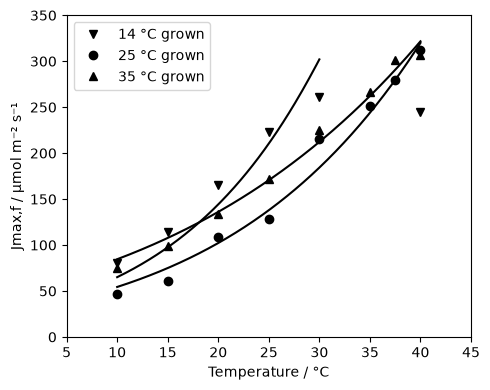

In [4]:
fig, axs = plt.subplots(nrows=1, ncols=1, figsize=(5, 4), squeeze=False)
ax0 = axs[0, 0]
ax0.plot(tables["g14"]["x"], tables["g14"]["Jf14"] * 202, color="black")
ax0.plot(tables["t"]["x"], tables["t"]["Jf25"] * 136.2, color="black")
ax0.plot(tables["t"]["x"], tables["t"]["Jf35"] * 173.8, color="black")
ax0.plot(data["T14"], data["J14"], color="black", ls="none", marker="v", label="14 °C grown")
ax0.plot(data["T"], data["J25"], color="black", ls="none", marker="o", label="25 °C grown")
ax0.plot(data["T"], data["J35"], color="black", ls="none", marker="^", label="35 °C grown")
ax0.set_xlabel("Temperature / °C")
ax0.set_ylabel("Jmax,f / µmol m⁻² s⁻¹")
ax0.set_xlim(5, 45)
ax0.set_ylim(0, 350)
ax0.legend()
plt.tight_layout()
plt.show()

## Figure 3: Jmax,f normalised to unity at 25 °C (Table 1)

In [5]:
data = {"T14":[10.5,15,17.5,30],"J14":[0.426,0.561,0.649,1.301],"T35":[10.5,12.5,15,17.5,20,27.5,30,32.5,35,37.5,39.7],"J35":[0.462,0.514,0.589,0.671,0.767,1.102,1.244,1.402,1.586,1.798,1.952]}
data = {k: np.array(c) for k, c in data.items()}
tables = {}

# Scan g14
to_scan = pd.DataFrame({"T_leaf": np.linspace(10, 30, 201)})
result = scan.steady_state(
    get_model(),
    to_scan=to_scan,
)
frame = result.combined
assert not frame[["Jf14"]].isna().any(axis=None)
tables["g14"] = {
    "x": to_scan["T_leaf"].to_numpy(),
    "Jf14": frame["Jf14"].to_numpy(),
}

# Scan t
to_scan = pd.DataFrame({"T_leaf": np.linspace(10, 40, 301)})
result = scan.steady_state(
    get_model(),
    to_scan=to_scan,
)
frame = result.combined
assert not frame[["Jf25","Jf35"]].isna().any(axis=None)
tables["t"] = {
    "x": to_scan["T_leaf"].to_numpy(),
    "Jf25": frame["Jf25"].to_numpy(),
    "Jf35": frame["Jf35"].to_numpy(),
}

  0%|          | 0/201 [00:00<?, ?it/s]

100%|██████████| 201/201 [00:00<00:00, 3397.40it/s]

  0%|          | 0/301 [00:00<?, ?it/s]

100%|██████████| 301/301 [00:00<00:00, 3423.25it/s]

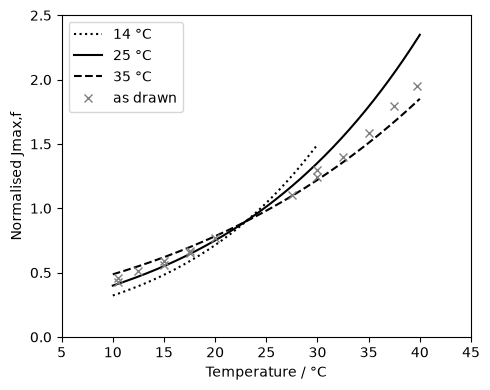

In [6]:
fig, axs = plt.subplots(nrows=1, ncols=1, figsize=(5, 4), squeeze=False)
ax0 = axs[0, 0]
ax0.plot(tables["g14"]["x"], tables["g14"]["Jf14"], color="black", ls=":", label="14 °C")
ax0.plot(tables["t"]["x"], tables["t"]["Jf25"], color="black", ls="-", label="25 °C")
ax0.plot(tables["t"]["x"], tables["t"]["Jf35"], color="black", ls="--", label="35 °C")
ax0.plot(data["T14"], data["J14"], color="grey", ls="none", marker="x", label="as drawn")
ax0.plot(data["T35"], data["J35"], color="grey", ls="none", marker="x")
ax0.set_xlabel("Temperature / °C")
ax0.set_ylabel("Normalised Jmax,f")
ax0.set_xlim(5, 45)
ax0.set_ylim(0, 2.5)
ax0.legend()
plt.tight_layout()
plt.show()

## Figure 4b,c: ΦPSII,max,l and ΘPSII against leaf temperature (Table 2)

In [7]:
tables = {}

# Scan t
to_scan = pd.DataFrame({"T_leaf": np.linspace(10, 40, 301)})
result = scan.steady_state(
    get_model(),
    to_scan=to_scan,
)
frame = result.combined
assert not frame[["Phi","Theta14","Theta","Theta35"]].isna().any(axis=None)
tables["t"] = {
    "x": to_scan["T_leaf"].to_numpy(),
    "Phi": frame["Phi"].to_numpy(),
    "Theta14": frame["Theta14"].to_numpy(),
    "Theta": frame["Theta"].to_numpy(),
    "Theta35": frame["Theta35"].to_numpy(),
}

  0%|          | 0/301 [00:00<?, ?it/s]

100%|██████████| 301/301 [00:00<00:00, 3301.92it/s]

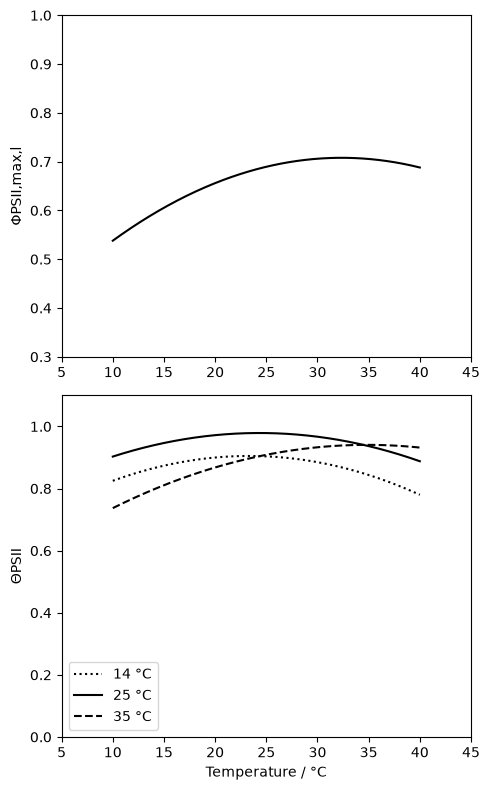

In [8]:
fig, axs = plt.subplots(nrows=2, ncols=1, figsize=(5, 8), squeeze=False)
ax0 = axs[0, 0]
ax0.plot(tables["t"]["x"], tables["t"]["Phi"], color="black")
ax0.set_ylabel("ΦPSII,max,l")
ax0.set_xlim(5, 45)
ax0.set_ylim(0.3, 1)
ax1 = axs[1, 0]
ax1.plot(tables["t"]["x"], tables["t"]["Theta14"], color="black", ls=":", label="14 °C")
ax1.plot(tables["t"]["x"], tables["t"]["Theta"], color="black", ls="-", label="25 °C")
ax1.plot(tables["t"]["x"], tables["t"]["Theta35"], color="black", ls="--", label="35 °C")
ax1.set_xlabel("Temperature / °C")
ax1.set_ylabel("ΘPSII")
ax1.set_xlim(5, 45)
ax1.set_ylim(0, 1.1)
ax1.legend()
plt.tight_layout()
plt.show()